In [5]:
import pandas as pd, numpy as np, blosc2
from pathlib import Path

d = Path("Data/FutureNetwork-data-labeled/labeled")
lab = pd.read_csv(d / "samples.csv")

print(lab.shape)
print(lab.groupby("layout").agg(rooms=("room", "nunique"), traces=("identifier", "count")))
print(pd.crosstab(lab.layout, lab.headcount))

i = lab.identifier.iloc[0]
csi = blosc2.load_array(str(d / f"CSI_{i}.b2"))
ati = blosc2.load_array(str(d / f"ATI_{i}.b2"))
print(i, csi.shape, csi.dtype, ati.shape)
print("ATI µs mean/std/min/max:", ati.mean(), ati.std(), ati.min(), ati.max())

amp = np.abs(csi[:600, 0])                 # true magnitude, (600, 3, 1024)
dyn = amp - amp.mean(axis=0, keepdims=True)
print("dynamic std:", dyn.std())

(48, 5)
         rooms  traces
layout                
a            1      12
b            1       1
c            1      12
e            1       3
g            1      17
unknown      1       3
headcount  0   1  2  3  4
layout                   
a          1   2  3  3  3
b          1   0  0  0  0
c          0   2  3  3  4
e          2   1  0  0  0
g          7  10  0  0  0
unknown    0   3  0  0  0
a_a1_hash813694_1 (12000, 1, 3, 1024) complex64 (12000,)
ATI µs mean/std/min/max: 5158.46 1505.5212 0.0 74613.0
dynamic std: 4.771323


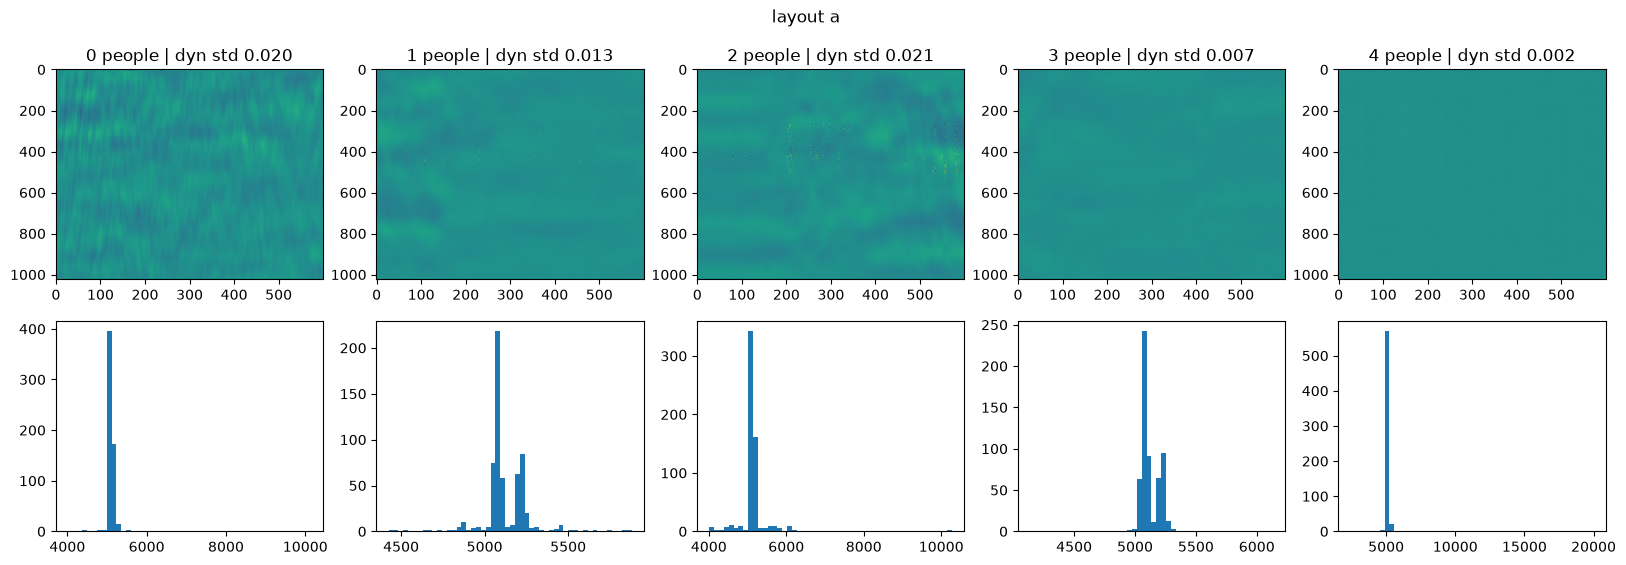

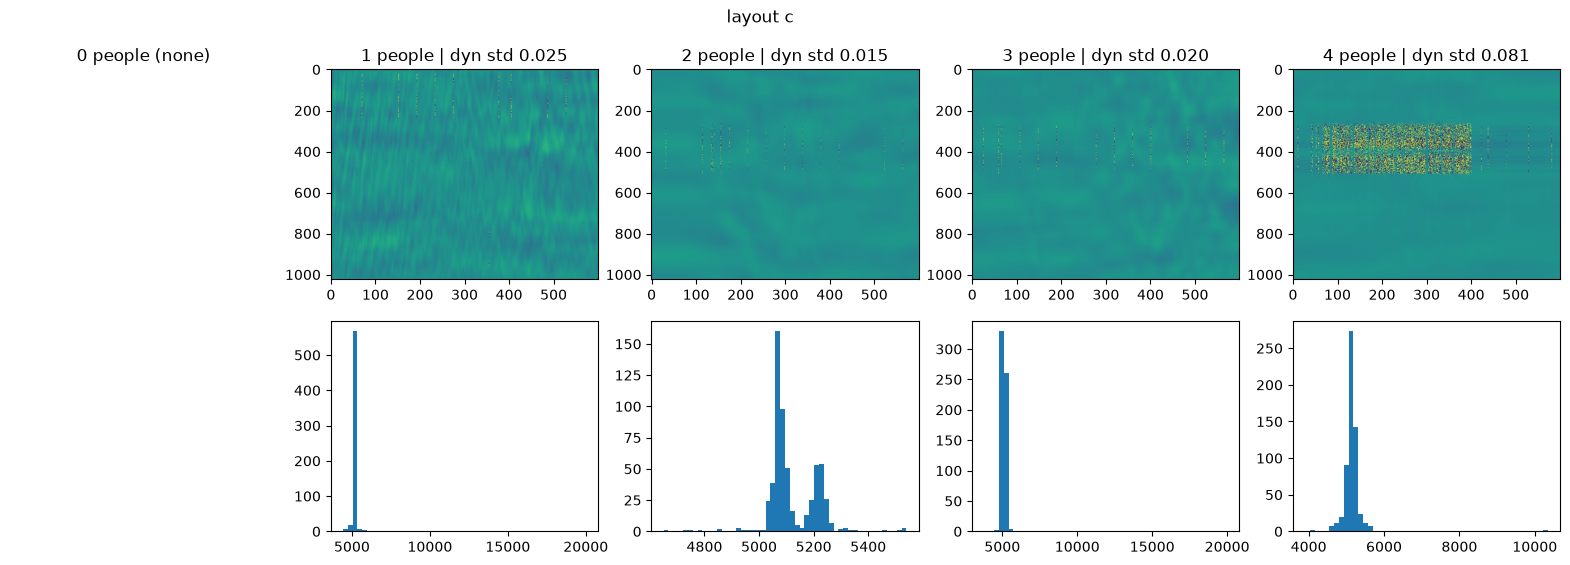

In [7]:
def plot_layout(layout, vmax=0.3):
    fig, axes = plt.subplots(2, 5, figsize=(20, 6))
    for k in range(5):
        rows = lab[(lab.layout == layout) & (lab.headcount == k)]
        if rows.empty:
            axes[0, k].set_title(f"{k} people (none)"); axes[0, k].axis("off"); axes[1, k].axis("off")
            continue
        csi, ati = load(rows.iloc[0].identifier)
        amp = np.abs(csi[:600, 0, 0, :])
        amp = amp / amp.mean()                       # remove overall gain
        dyn = amp - amp.mean(axis=0, keepdims=True)  # remove static part
        axes[0, k].imshow(dyn.T, aspect="auto", cmap="viridis", vmin=-vmax, vmax=vmax)
        axes[0, k].set_title(f"{k} people | dyn std {dyn.std():.3f}")
        axes[1, k].hist(np.clip(ati[:600], 0, 20000), bins=50)
    plt.suptitle(f"layout {layout}")
    plt.show()

plot_layout("a")
plot_layout("c")

In [3]:
import numpy as np
def window_features(csi, ati):
    """Extract features from a window of CSI data."""
    amp = np.abs(csi[:, 0])                       # (600, 3, 1024)
    amp = amp / (amp.mean() + 1e-9)               # remove room/gain scale
    dyn = amp - amp.mean(axis=0, keepdims=True)
    f = []
    f += list(dyn.std(axis=(0, 2)))               # dynamic energy per Rx (3)
    f += [np.abs(np.diff(amp, axis=0)).mean()]    # frame-to-frame change
    a, b = amp[:-1].reshape(599, -1), amp[1:].reshape(599, -1)
    f += [np.mean([np.corrcoef(a[t], b[t])[0, 1] for t in range(0, 599, 20)])]
    ph = np.angle(csi[:, 0, 0] * np.conj(csi[:, 0, 1]))  # phase diff Rx0-Rx1
    f += [ph.std(axis=0).mean()]
    ati = np.asarray(ati, dtype=np.float64)
    f += [np.median(ati), ati.std(), np.percentile(ati, 99), (ati == 0).mean()]
    return np.array(f, dtype=np.float32)

X, y, layouts, traces = [], [], [], []
for _, r in lab.iterrows():
    csi, ati = load(r.identifier)
    for s in range(0, 12000 - 599, 600):          # 20 non-overlapping windows
        X.append(window_features(csi[s:s+600], ati[s:s+600]))
        y.append(int(r.headcount)); layouts.append(r.layout); traces.append(r.identifier)
X, y = np.array(X), np.array(y)
np.savez("features.npz", X=X, y=y, layouts=layouts, traces=traces)

In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

z = np.load("features.npz")
X, y, layouts = np.nan_to_num(z["X"]), z["y"], z["layouts"]

def run(name, cols=None):
    for held in ["a", "c", "g"]:
        te = layouts == held; tr = ~te
        Xs = X if cols is None else X[:, cols]
        if name == "dummy":
            m = DummyClassifier(strategy="most_frequent")
        else:
            m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
        m.fit(Xs[tr], y[tr])
        print(f"{name:10s} held-out {held}: {m.score(Xs[te], y[te]):.2f}")

run("dummy")                         # baseline 1
run("ATI only", list(range(6, 10)))  # baseline 2
run("all feats")                     # baseline 3

dummy      held-out a: 0.17
dummy      held-out c: 0.17
dummy      held-out g: 0.59
ATI only   held-out a: 0.17
ATI only   held-out c: 0.20
ATI only   held-out g: 0.41
all feats  held-out a: 0.14
all feats  held-out c: 0.20
all feats  held-out g: 0.46


In [6]:
import numpy as np, pandas as pd, blosc2
from pathlib import Path

d = Path("Data/FutureNetwork-data-labeled/labeled")
lab = pd.read_csv(d / "samples.csv")

W, I, Y, L, T = [], [], [], [], []
for _, r in lab.iterrows():
    csi = blosc2.load_array(str(d / f"CSI_{r.identifier}.b2"))
    ati = blosc2.load_array(str(d / f"ATI_{r.identifier}.b2"))
    for s in range(0, 12000 - 599, 600):
        amp = np.abs(csi[s:s+600, 0])                       # (600, 3, 1024)
        amp = amp.reshape(600, 3, 64, 16).mean(axis=3)      # (600, 3, 64)
        itv = ati[s:s+600].copy(); itv[-1] = 0
        W.append(amp.astype(np.float16)); I.append(itv)
        Y.append(int(r.headcount)); L.append(r.layout); T.append(r.identifier)
np.savez("windows.npz", W=np.array(W), I=np.array(I), y=np.array(Y),
         layouts=np.array(L), traces=np.array(T))

In [7]:
import numpy as np, torch
from torch import nn

z = np.load("windows.npz")
W = torch.tensor(z["W"].astype(np.float32)); y = torch.tensor(z["y"])
layouts = z["layouts"]

def prep(x):                                   # x: (N, 600, 3, 64) raw amplitude
    x = x / (x.mean(dim=(1, 2, 3), keepdim=True) + 1e-6)   # remove gain
    x = x - x.mean(dim=1, keepdim=True)                    # remove static part
    return x.reshape(x.shape[0], 600, 192).permute(0, 2, 1)  # (N, 192, 600)

def make_net():
    return nn.Sequential(
        nn.Conv1d(192, 32, 9, stride=2, padding=4), nn.ReLU(),
        nn.Conv1d(32, 32, 9, stride=2, padding=4), nn.ReLU(),
        nn.Conv1d(32, 32, 9, stride=2, padding=4), nn.ReLU(),
        nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(32, 5))

for held in ["a", "c", "g"]:
    te = torch.tensor(layouts == held); tr = ~te
    Xtr, ytr, Xte, yte = prep(W[tr]), y[tr], prep(W[te]), y[te]
    net = make_net(); opt = torch.optim.AdamW(net.parameters(), 1e-3, weight_decay=1e-2)
    for ep in range(30):
        net.train()
        for idx in torch.randperm(len(Xtr)).split(32):
            opt.zero_grad()
            nn.functional.cross_entropy(net(Xtr[idx]), ytr[idx]).backward()
            opt.step()
    net.eval()
    with torch.no_grad():
        acc = (net(Xte).argmax(1) == yte).float().mean().item()
    print(f"CNN held-out {held}: {acc:.2f}")

CNN held-out a: 0.10
CNN held-out c: 0.21
CNN held-out g: 0.21


In [8]:
import numpy as np, torch
from torch import nn

z = np.load("windows.npz")
W = torch.tensor(z["W"].astype(np.float32)); y = torch.tensor(z["y"])

def prep(x):
    x = x / (x.mean(dim=(1, 2, 3), keepdim=True) + 1e-6)
    x = x - x.mean(dim=1, keepdim=True)
    return x.reshape(x.shape[0], 600, 192).permute(0, 2, 1)

net = nn.Sequential(
    nn.Conv1d(192, 32, 9, stride=2, padding=4), nn.ReLU(),
    nn.Conv1d(32, 32, 9, stride=2, padding=4), nn.ReLU(),
    nn.Conv1d(32, 32, 9, stride=2, padding=4), nn.ReLU(),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(32, 5))

X = prep(W)
opt = torch.optim.AdamW(net.parameters(), 1e-3, weight_decay=1e-2)
for ep in range(30):
    net.train()
    for idx in torch.randperm(len(X)).split(32):
        opt.zero_grad()
        nn.functional.cross_entropy(net(X[idx]), y[idx]).backward()
        opt.step()
torch.save(net.state_dict(), "cnn.pt")

In [9]:
import torch, numpy as np, onnxruntime as ort
from torch import nn
from time import perf_counter

class Submission(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
    def forward(self, frames, intervals):
        f = frames[:, 0]                                        # (600, 3, 1024, 2)
        amp = torch.sqrt(f[..., 0] ** 2 + f[..., 1] ** 2)       # (600, 3, 1024)
        amp = amp.reshape(600, 3, 64, 16).mean(dim=3)           # (600, 3, 64)
        amp = amp / (amp.mean() + 1e-6)
        amp = amp - amp.mean(dim=0, keepdim=True)
        x = amp.reshape(600, 192).permute(1, 0).unsqueeze(0)    # (1, 192, 600)
        return self.net(x)[0]                                   # (5,)

net.load_state_dict(torch.load("cnn.pt")); net.eval()
model = Submission(net).eval()

frames = torch.randn(600, 1, 3, 1024, 2)
intervals = torch.full((600,), 5000.0)
torch.onnx.export(model, (frames, intervals), "model.onnx",
                  input_names=["frames", "intervals"], output_names=["logits"],
                  opset_version=18, external_data=False)

W1017 19:27:49.784000 11660 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1017 19:27:49.786000 11660 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1017 19:27:49.787000 11660 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1017 19:27:49.788000 11660 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `Submission([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Submission([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 18},
            producer_name='pytorch',
            producer_version='2.14.1+cpu',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"frames"<FLOAT,[600,1,3,1024,2]>,
                %"intervals"<FLOAT,[600]>
            ),
            outputs=(
                %"logits"<FLOAT,[5]>
            ),
            initializers=(
                %"net.0.weight"<FLOAT,[32,192,9]>{TorchTensor(...)},
                %"net.0.bias"<FLOAT,[32]>{TorchTensor(...)},
                %"net.2.weight"<FLOAT,[32,32,9]>{TorchTensor(...)},
                %"net.2.bias"<FLOAT,[32]>{TorchTensor(...)},
                %"net.4.weight"<FLOAT,[32,32,9]>{TorchTensor(...)},
                %"net.4.bias"<FLOAT,[32]>{TorchTensor(...)},
                %"net.9.weight"<FLOAT,[5,32]>{TorchTensor(...)},
                %"net.9.bias"

In [11]:
import blosc2, numpy as np, pandas as pd, torch
from pathlib import Path
from time import perf_counter

d = Path("Data/FutureNetwork-data-labeled/labeled")
lab = pd.read_csv(d / "samples.csv")
i = lab.identifier.iloc[0]
csi = blosc2.load_array(str(d / f"CSI_{i}.b2"))
ati = blosc2.load_array(str(d / f"ATI_{i}.b2"))

real_frames = np.ascontiguousarray(csi[:600]).view(np.float32).reshape(600, 1, 3, 1024, 2)
real_intervals = ati[:600].copy()
real_intervals[-1] = 0

print([x.name for x in sess.get_inputs()])   # should list frames AND intervals
out = sess.run(["logits"], {"frames": real_frames, "intervals": real_intervals})[0]
ref = model(torch.from_numpy(real_frames), torch.from_numpy(real_intervals)).detach().numpy()
print(out, ref)

t = perf_counter()
sess.run(["logits"], {"frames": real_frames, "intervals": real_intervals})
print("time:", perf_counter() - t)

['frames', 'intervals']
[ 0.44402102  4.697696   -1.9946012  -2.7728105  -7.398714  ] [ 0.44377187  4.697057   -1.994231   -2.7723355  -7.398105  ]
time: 0.005718000000342727


In [12]:
sess = ort.InferenceSession("model.onnx", providers=["CPUExecutionProvider"])
out = sess.run(["logits"], {"frames": real_frames, "intervals": real_intervals})[0]
print(out, model(torch.from_numpy(real_frames), torch.from_numpy(real_intervals)).detach().numpy())
t = perf_counter(); sess.run(["logits"], {"frames": real_frames, "intervals": real_intervals}); print(perf_counter() - t)

[ 0.44402102  4.697696   -1.9946012  -2.7728105  -7.398714  ] [ 0.44377187  4.697057   -1.994231   -2.7723355  -7.398105  ]
0.005357599999115337
